# 02 — LP-FT Baseline (Focal Loss + Alpha Balanced)

**Protocol LP-FT:**
- Phase 1: 8 epochs, head only (base.trainable=False), LR=1e-3
- Phase 2: 25 epochs, full unfreeze, LR=1e-5

**Loss:** Focal Loss cu alpha balanced (sklearn-style inverse frequency, normalized).
Diferit față de notebook 01 (sparse CCE + class_weight) — aici testăm dacă focal loss
îmbunătățește minoritățile (df, vasc).

**Output:** `experiments/efficientnetv2b0/tier{1-5}/B_lpft/`


## 1. Setup


In [1]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Mounted at /content/drive
Drive mounted


In [2]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import backend as K
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_fscore_support,
)

# ─── REPRODUCIBILITY ───
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [3]:
# ─── PATHS ───
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
EXPERIMENTS_DIR = DRIVE_BASE / 'experiments' / 'efficientnetv2b0'
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

# ─── HYPERPARAMETERS ───
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
DENSE1_UNITS = 1024
DENSE2_UNITS = 256
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

PAPER_TRAINABLE_PARAMS = 7_437_207
PAPER_ACCURACY = 86.74

# ─── LABELS ───
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords:   {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2:       {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Experiments: {EXPERIMENTS_DIR}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shards')
    else:
        print(f'  [WARNING] {split}/ missing!')

TFRecords:   True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2:       True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Experiments: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0
  val: 3 shards
  test: 3 shards
  tier5: 21 shards


## 2. Data pipeline


In [4]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['lesion_id']


def decode_with_source(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['source']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool: {len(TRAIN_FILES)} shards')
print(f'Val:        {len(VAL_FILES)} shards')
print(f'Test:       {len(TEST_FILES)} shards')

Train pool: 21 shards
Val:        3 shards
Test:       3 shards


In [5]:
def get_tier_lesion_ids(tier):
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())


def make_lesion_filter(allowed_ids):
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    return tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )


for t in [1, 2, 3, 4, 5]:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_ids')

Tier 1: 5,987 lesion_ids
Tier 2: 7,276 lesion_ids
Tier 3: 8,565 lesion_ids
Tier 4: 9,855 lesion_ids
Tier 5: no filter (full tier5)


In [6]:
# ─── Augmentation: flip + rotation ±20° + zoom ±10% ───
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    tf.keras.layers.RandomRotation(
        factor=ROTATION_MAX_DEG / 360.0,
        fill_mode='reflect', seed=SEED,
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-ZOOM_RANGE, ZOOM_RANGE),
        width_factor=(-ZOOM_RANGE, ZOOM_RANGE),
        fill_mode='reflect', seed=SEED,
    ),
], name='paper_augmentation')


def preprocess_efficientnet(img_01):
    """Input [0,1] → [-1,1]."""
    return (img_01 * 255.0) / 127.5 - 1.0


print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [7]:
def build_train_ds(tier, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Train ds — repeat + filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    # Augmentation layer per call (allows different rotation/zoom in Optuna)
    aug = tf.keras.Sequential([
        tf.keras.layers.RandomFlip('horizontal_and_vertical', seed=SEED),
        tf.keras.layers.RandomRotation(
            factor=rotation_deg / 360.0,
            fill_mode='reflect', seed=SEED,
        ),
        tf.keras.layers.RandomZoom(
            height_factor=(-zoom, zoom),
            width_factor=(-zoom, zoom),
            fill_mode='reflect', seed=SEED,
        ),
    ])

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda img, lbl, lid: tf.equal(table.lookup(lid), 1))

    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda img, lbl: (aug(img, training=True), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.map(
        lambda img, lbl: (preprocess_efficientnet(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files, with_source=False):
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if with_source:
        ds = ds.map(decode_with_source, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl, src: (preprocess_efficientnet(img), lbl, src),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    else:
        ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl: (preprocess_efficientnet(img), lbl),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [9]:
def count_tier_samples(tier):
    allowed_ids = get_tier_lesion_ids(tier)
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))
    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
print('Counting samples per tier (~1-2 min):')
for t in [1, 2, 3, 4, 5]:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples')

val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,}')
print(f'Test: {test_count:,}')

Counting samples per tier (~1-2 min):
  Tier 1:  8,042 samples
  Tier 2: 10,996 samples
  Tier 3: 14,061 samples
  Tier 4: 17,300 samples
  Tier 5: 20,299 samples

Val:  2,519
Test: 2,513


## 3. Focal loss + alpha balanced


In [10]:
def compute_alpha_inverse_frequency(distribution, normalize=True):
    """sklearn 'balanced' alpha. Output: array de shape (num_classes,)."""
    counts = np.array([distribution[i] for i in range(NUM_CLASSES)], dtype=np.float32)
    total = counts.sum()
    alpha = total / (NUM_CLASSES * counts)
    if normalize:
        alpha = alpha / alpha.max()
    return alpha


def categorical_focal_loss(alpha, gamma=2.0):
    """Categorical focal loss cu alpha per clasa.

    FL(p_t) = -α_t · (1 - p_t)^γ · log(p_t)

    Folosim sparse labels (int) → one-hot intern.
    """
    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss(y_true, y_pred):
        # y_true vine ca int64 (labels), y_pred ca probabilități softmax
        y_true_oh = tf.one_hot(tf.cast(y_true, tf.int32), depth=NUM_CLASSES)
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
        ce = -y_true_oh * tf.math.log(y_pred)
        focal_weight = tf.pow(1.0 - y_pred, gamma)
        weighted_loss = alpha * focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(weighted_loss, axis=-1))

    return loss


# Sanity check pe Tier 5
alpha_t5 = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[5])
print('Alpha for Tier 5 (normalized to max=1):')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name}: {alpha_t5[i]:.4f}')

Alpha for Tier 5 (normalized to max=1):
  akiec: 0.1544
  bcc: 0.0691
  bkl: 0.0865
  df: 1.0000
  mel: 0.0507
  nv: 0.0179
  vasc: 0.8804


## 4. Model


In [11]:
def build_efficientnetv2b0(
    dense1=DENSE1_UNITS, dense2=DENSE2_UNITS, dropout=DROPOUT_RATE,
    base_trainable=True, verbose=True,
):
    """Strict Nawaz Table 4 — Total 7,500,375 / Trainable 7,437,207 (with full unfreeze)."""
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.EfficientNetV2B0(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = base_trainable

    # CRITICAL: training=False chiar și pentru bază unfrozen (BN folosește moving avg).
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(dense1, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(dense2, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name='EfficientNetV2B0')
    model.base_model = base

    if verbose:
        total = model.count_params()
        trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
        print(f'  Total: {total:,} | Trainable: {trainable:,}')
    return model


def set_phase_1(model):
    """Phase 1: head only."""
    model.base_model.trainable = False
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 1] Trainable: {trainable:,}')


def set_phase_2(model):
    """Phase 2: full unfreeze (BN stays frozen via training=False)."""
    model.base_model.trainable = True
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 2] Trainable: {trainable:,}')


_test = build_efficientnetv2b0()
del _test
tf.keras.backend.clear_session()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
  Total: 7,500,375 | Trainable: 7,437,207


## 5. LP-FT training


In [12]:
# ─── LP-FT CONFIG ───
LPFT_CONFIG = {
    'phase1_epochs': 8,
    'phase1_lr': 1e-3,
    'phase1_patience': 3,
    'phase2_epochs': 25,
    'phase2_lr': 1e-5,
    'phase2_patience': 5,
    'focal_gamma': 2.0,
}

TIERS_TO_RUN = [1, 2, 3, 4, 5]
print(f'Tiers: {TIERS_TO_RUN}')
print(f'Config: {LPFT_CONFIG}')


Tiers: [1, 2, 3, 4, 5]
Config: {'phase1_epochs': 8, 'phase1_lr': 0.001, 'phase1_patience': 3, 'phase2_epochs': 25, 'phase2_lr': 1e-05, 'phase2_patience': 5, 'focal_gamma': 2.0}


In [13]:
def get_callbacks(tier_dir, phase_name, patience):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / f'best_{phase_name}.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=patience, restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=max(2, patience // 2), min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / f'log_{phase_name}.csv'), append=False,
        ),
    ]


In [16]:
def evaluate_model(model, ds, label='test'):
    """Evaluate cu accuracy, precision, recall, F1, AUC, confusion matrix."""
    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0,
    )
    macro_f1 = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0,
    )[2]
    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, zero_division=0,
    )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc,
        'precision': float(prec),
        'recall': float(rec),
        'weighted_f1': float(f1),
        'macro_f1': float(macro_f1),
        'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }

In [14]:
def train_tier_lpft(tier):
    tier_dir = EXPERIMENTS_DIR / f'tier{tier}' / 'B_lpft'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'results.json'
    if results_path.exists():
        print(f'\n⏭  Tier {tier} LP-FT already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}\n# TIER {tier} — LP-FT\n#  Output: {tier_dir}\n{"#"*70}')
    start = time.time()

    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    # Datasets
    train_ds = build_train_ds(tier)
    val_ds = build_eval_ds(VAL_FILES)
    test_ds = build_eval_ds(TEST_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Train samples: {train_samples:,} | Steps/epoch: {steps_per_epoch}')

    # Alpha pentru focal loss
    alpha = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[tier])
    print(f'  Alpha: {[f"{a:.3f}" for a in alpha]}')

    # ─── Model + Phase 1 ───
    model = build_efficientnetv2b0()
    set_phase_1(model)

    loss_fn = categorical_focal_loss(alpha=alpha, gamma=LPFT_CONFIG['focal_gamma'])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LPFT_CONFIG['phase1_lr']),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    print(f'\n--- PHASE 1: head only, LR={LPFT_CONFIG["phase1_lr"]} ---')
    history_p1 = model.fit(
        train_ds, validation_data=val_ds,
        epochs=LPFT_CONFIG['phase1_epochs'],
        steps_per_epoch=steps_per_epoch,
        callbacks=get_callbacks(tier_dir, 'phase1', LPFT_CONFIG['phase1_patience']),
        verbose=1,
    )

    # ─── Phase 2 ───
    set_phase_2(model)
    # MUST recompile cu LR mic
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LPFT_CONFIG['phase2_lr']),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    print(f'\n--- PHASE 2: full unfreeze, LR={LPFT_CONFIG["phase2_lr"]} ---')
    history_p2 = model.fit(
        train_ds, validation_data=val_ds,
        epochs=LPFT_CONFIG['phase2_epochs'],
        steps_per_epoch=steps_per_epoch,
        callbacks=get_callbacks(tier_dir, 'phase2', LPFT_CONFIG['phase2_patience']),
        verbose=1,
    )

    # Combined history
    combined = {}
    for k in history_p1.history:
        combined[k] = history_p1.history[k] + history_p2.history.get(k, [])

    # ─── Evaluate ───
    val_metrics = evaluate_model(model, val_ds, label=f'tier{tier}_val')
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')

    # Plots
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(combined['accuracy'], label='Train')
    axes[0].plot(combined['val_accuracy'], label='Val')
    axes[0].axvline(x=len(history_p1.history['loss']) - 0.5, color='gray', linestyle=':', label='P1→P2')
    axes[0].axhline(y=PAPER_ACCURACY/100, color='r', linestyle='--', label=f'Paper ({PAPER_ACCURACY}%)')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(combined['loss'], label='Train')
    axes[1].plot(combined['val_loss'], label='Val')
    axes[1].axvline(x=len(history_p1.history['loss']) - 0.5, color='gray', linestyle=':')
    axes[1].set_title(f'Tier {tier} — Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    cm = np.array(test_metrics['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    axes[2].set_title(f'Tier {tier} — Test CM'); axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(tier_dir / 'plots.png', dpi=120, bbox_inches='tight')
    plt.show()

    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'experiment': 'B_lpft',
        'train_samples': train_samples,
        'phase1_epochs_run': len(history_p1.history['loss']),
        'phase2_epochs_run': len(history_p2.history['loss']),
        'time_minutes': elapsed_min,
        'val': val_metrics,
        'test': test_metrics,
        'config': LPFT_CONFIG,
        'alpha': alpha.tolist(),
        'history': {k: [float(x) for x in v] for k, v in combined.items()},
    }
    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)

    model.save(tier_dir / 'final.keras')

    print(f'\n✓ Tier {tier} done in {elapsed_min:.1f} min')
    print(f'  Test accuracy: {test_metrics["accuracy"]*100:.2f}% (paper: {PAPER_ACCURACY:.2f}%)')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc; gc.collect()

    return results



######################################################################
# TIER 1 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/B_lpft
######################################################################
  Train samples: 8,042 | Steps/epoch: 250
  Alpha: ['0.347', '0.235', '0.105', '1.000', '0.102', '0.017', '0.853']
  Total: 7,500,375 | Trainable: 7,437,207
[Phase 1] Trainable: 1,578,503

--- PHASE 1: head only, LR=0.001 ---
Epoch 1/8
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1214 - loss: 0.2005
Epoch 1: val_accuracy improved from None to 0.00953, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/B_lpft/best_phase1.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 57s 123ms/step - accuracy: 0.1252 - loss: 0.1790 - val_accuracy: 0.0095 - val_loss: 0.1665 - learning_rate: 0.0010
Epoch 2/8
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1494 - loss: 0.1498
Epoch 2: val_accuracy improved from 0.00953 to 0.09925, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier1/B_lpft/best_phase1.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - accuracy: 0.1456 - loss: 0.1477 - val_accuracy: 0.0992 - val_loss: 0.1805 - learning_rate: 0.0010
Epoch 3/8
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1245 - loss: 0.1408
Epoch 3: val_accuracy did not improve from 0.09925

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
2

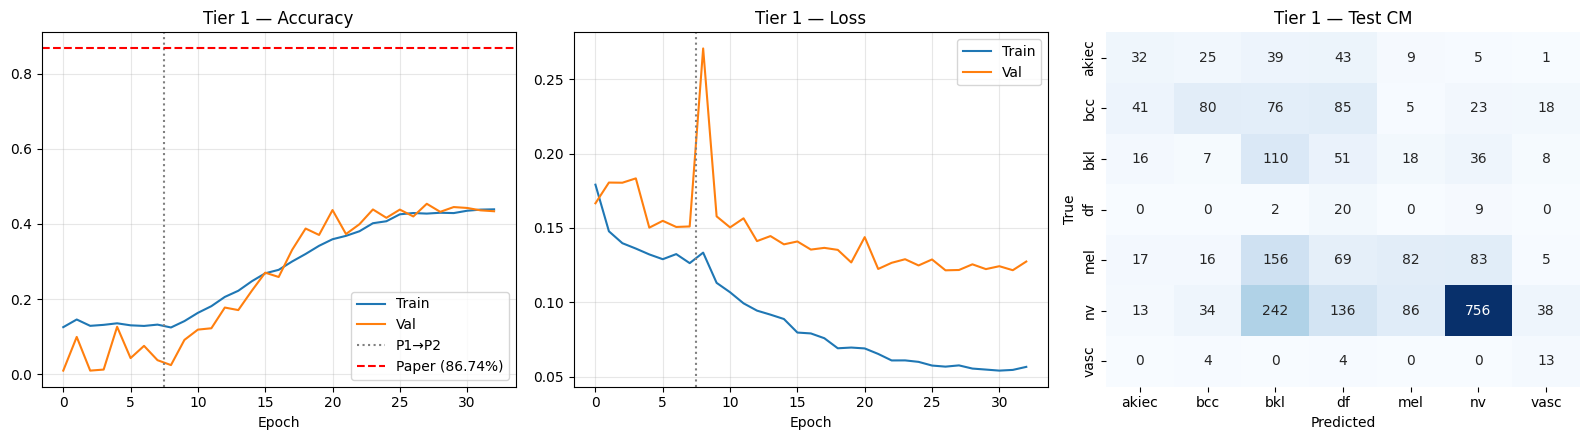


✓ Tier 1 done in 13.4 min
  Test accuracy: 43.49% (paper: 86.74%)

######################################################################
# TIER 2 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/B_lpft
######################################################################
  Train samples: 10,996 | Steps/epoch: 342
  Alpha: ['0.235', '0.127', '0.100', '1.000', '0.074', '0.018', '0.881']
  Total: 7,500,375 | Trainable: 7,437,207
[Phase 1] Trainable: 1,578,503

--- PHASE 1: head only, LR=0.001 ---
Epoch 1/8
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.1468 - loss: 0.1656
Epoch 1: val_accuracy improved from None to 0.18499, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier2/B_lpft/best_phase1.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 61s 100ms/step - accuracy: 0.1521 - loss: 0.1547 - val_accuracy: 0.1850 - val_loss: 0.1434 - learning_rate: 0.0010
Epoch 2/8
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.1453 - loss: 0.1272
Epoch 2: val_accuracy did not improve from 0.18499
342/342 ━━━━━━━━━━━━━━━━━━━━ 22s 66ms/step - accuracy: 0.1444 - loss: 0.1326 - val_accuracy: 0.1044 - val_loss: 0.1337 - learning_rate: 0.0010
Epoch 3/8
341/342 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.1311 - loss: 0.1245
Epoch 3: val_accuracy did not improve from 0.18499
342/342 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.1383 - loss: 0.1261 - val_accuracy: 0.0516 - val_loss: 0.1151 - learning_rate: 0.0010
Epoch 4/8
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.1340 - loss: 0.1225
Epoch 4: val_accuracy improved from 0.18499 to 0.18976, saving model to /content/driv

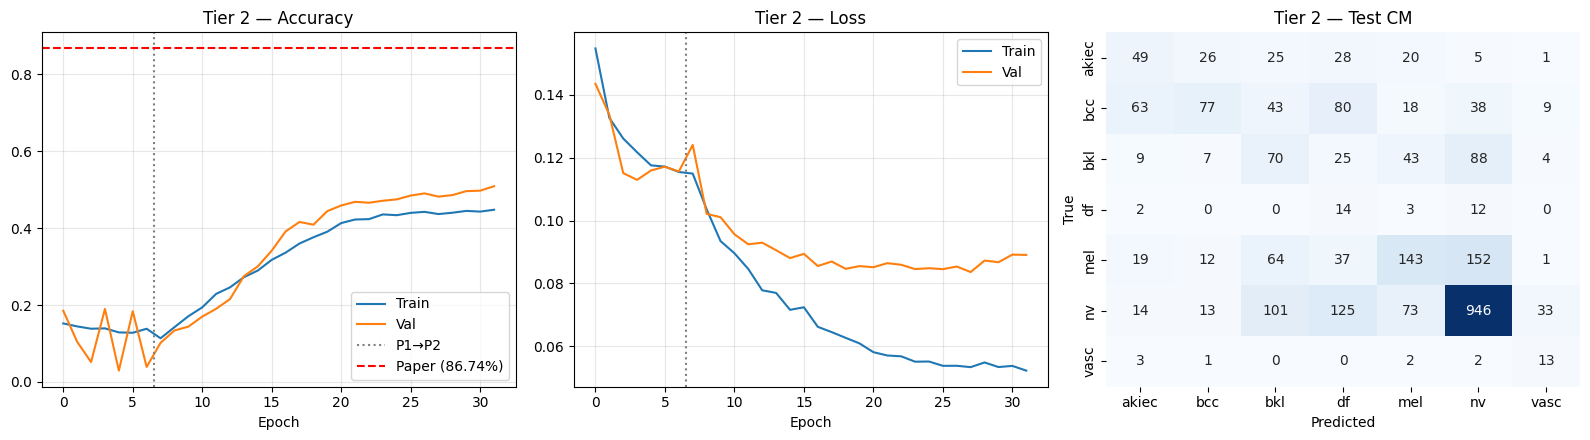


✓ Tier 2 done in 17.0 min
  Test accuracy: 52.21% (paper: 86.74%)

######################################################################
# TIER 3 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/B_lpft
######################################################################
  Train samples: 14,061 | Steps/epoch: 438
  Alpha: ['0.192', '0.092', '0.092', '1.000', '0.060', '0.018', '0.873']
  Total: 7,500,375 | Trainable: 7,437,207
[Phase 1] Trainable: 1,578,503

--- PHASE 1: head only, LR=0.001 ---
Epoch 1/8
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.1523 - loss: 0.1470
Epoch 1: val_accuracy improved from None to 0.01072, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/B_lpft/best_phase1.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 66s 91ms/step - accuracy: 0.1574 - loss: 0.1377 - val_accuracy: 0.0107 - val_loss: 0.1372 - learning_rate: 0.0010
Epoch 2/8
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.1336 - loss: 0.1212
Epoch 2: val_accuracy improved from 0.01072 to 0.12862, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier3/B_lpft/best_phase1.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 29s 65ms/step - accuracy: 0.1464 - loss: 0.1207 - val_accuracy: 0.1286 - val_loss: 0.1095 - learning_rate: 0.0010
Epoch 3/8
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.1295 - loss: 0.1087
Epoch 3: val_accuracy improved from 0.12862 to 0.13418, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0

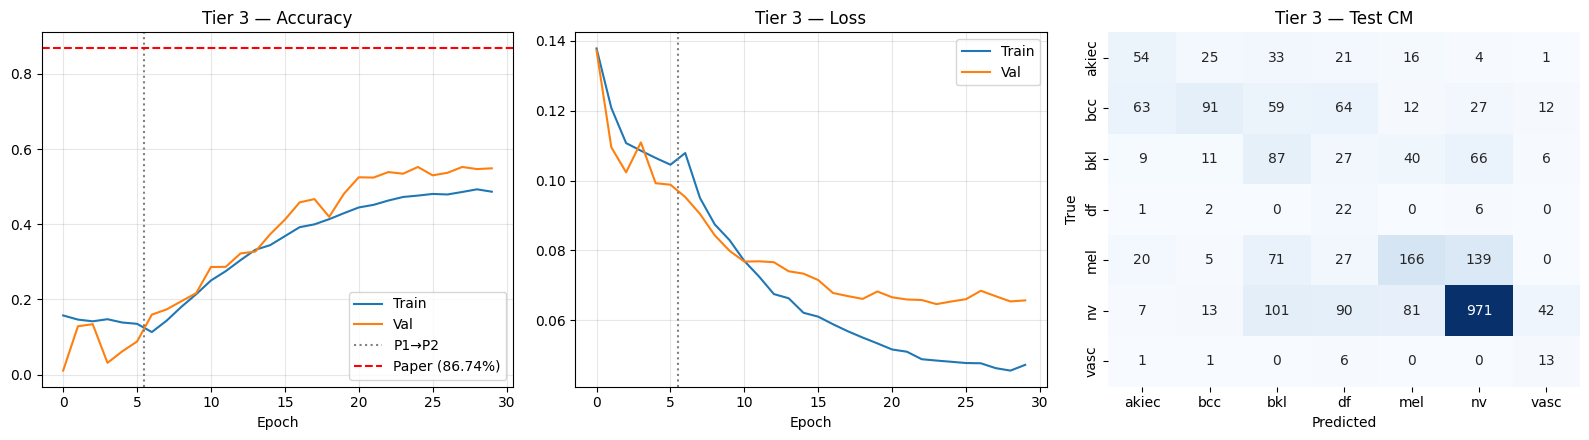


✓ Tier 3 done in 18.1 min
  Test accuracy: 55.87% (paper: 86.74%)

######################################################################
# TIER 4 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/B_lpft
######################################################################
  Train samples: 17,300 | Steps/epoch: 539
  Alpha: ['0.173', '0.079', '0.089', '1.000', '0.054', '0.018', '0.850']
  Total: 7,500,375 | Trainable: 7,437,207
[Phase 1] Trainable: 1,578,503

--- PHASE 1: head only, LR=0.001 ---
Epoch 1/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1612 - loss: 0.1370
Epoch 1: val_accuracy improved from None to 0.13220, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/B_lpft/best_phase1.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 72s 84ms/step - accuracy: 0.1619 - loss: 0.1284 - val_accuracy: 0.1322 - val_loss: 0.1251 - learning_rate: 0.0010
Epoch 2/8
538/539 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1364 - loss: 0.1112
Epoch 2: val_accuracy improved from 0.13220 to 0.14450, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier4/B_lpft/best_phase1.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 74s 137ms/step - accuracy: 0.1554 - loss: 0.1133 - val_accuracy: 0.1445 - val_loss: 0.1000 - learning_rate: 0.0010
Epoch 3/8
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.1347 - loss: 0.1047
Epoch 3: val_accuracy did not improve from 0.14450
539/539 ━━━━━━━━━━━━━━━━━━━━ 34s 63ms/step - accuracy: 0.1448 - loss: 0.1065 -

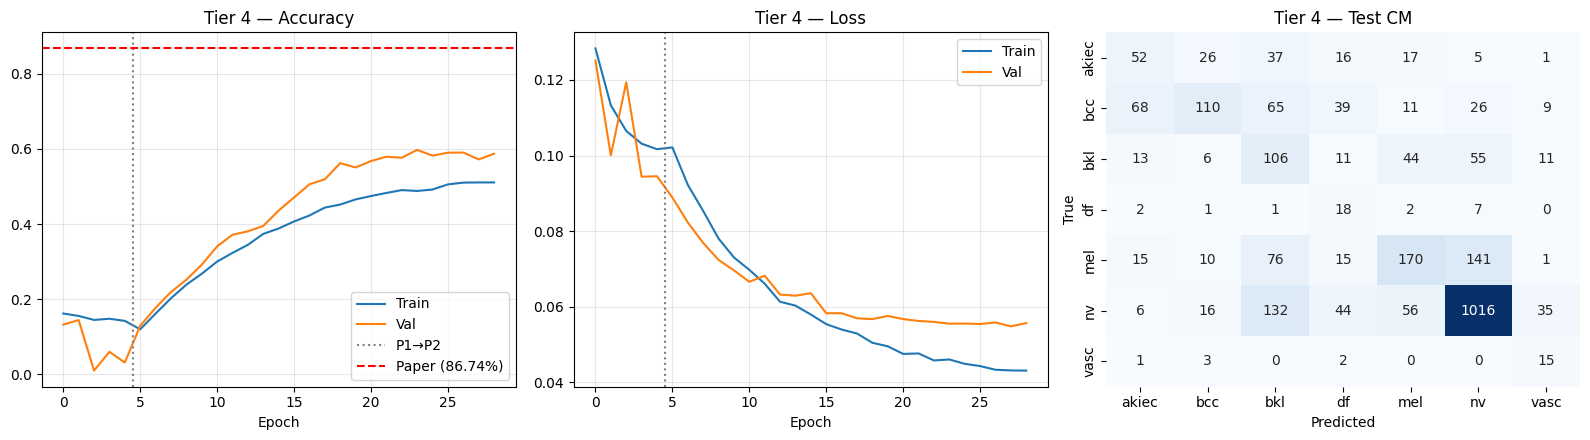


✓ Tier 4 done in 20.7 min
  Test accuracy: 59.17% (paper: 86.74%)

######################################################################
# TIER 5 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/B_lpft
######################################################################
  Train samples: 20,299 | Steps/epoch: 633
  Alpha: ['0.154', '0.069', '0.086', '1.000', '0.051', '0.018', '0.880']
  Total: 7,500,375 | Trainable: 7,437,207
[Phase 1] Trainable: 1,578,503

--- PHASE 1: head only, LR=0.001 ---
Epoch 1/8
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.1593 - loss: 0.1280
Epoch 1: val_accuracy improved from None to 0.02858, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/B_lpft/best_phase1.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 77s 80ms/step - accuracy: 0.1601 - loss: 0.1211 - val_accuracy: 0.0286 - val_loss: 0.0995 - learning_rate: 0.0010
Epoch 2/8
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.1498 - loss: 0.1041
Epoch 2: val_accuracy improved from 0.02858 to 0.05915, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/tier5/B_lpft/best_phase1.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 39s 62ms/step - accuracy: 0.1613 - loss: 0.1073 - val_accuracy: 0.0592 - val_loss: 0.0904 - learning_rate: 0.0010
Epoch 3/8
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.1389 - loss: 0.0958
Epoch 3: val_accuracy improved from 0.05915 to 0.15562, saving model to /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0

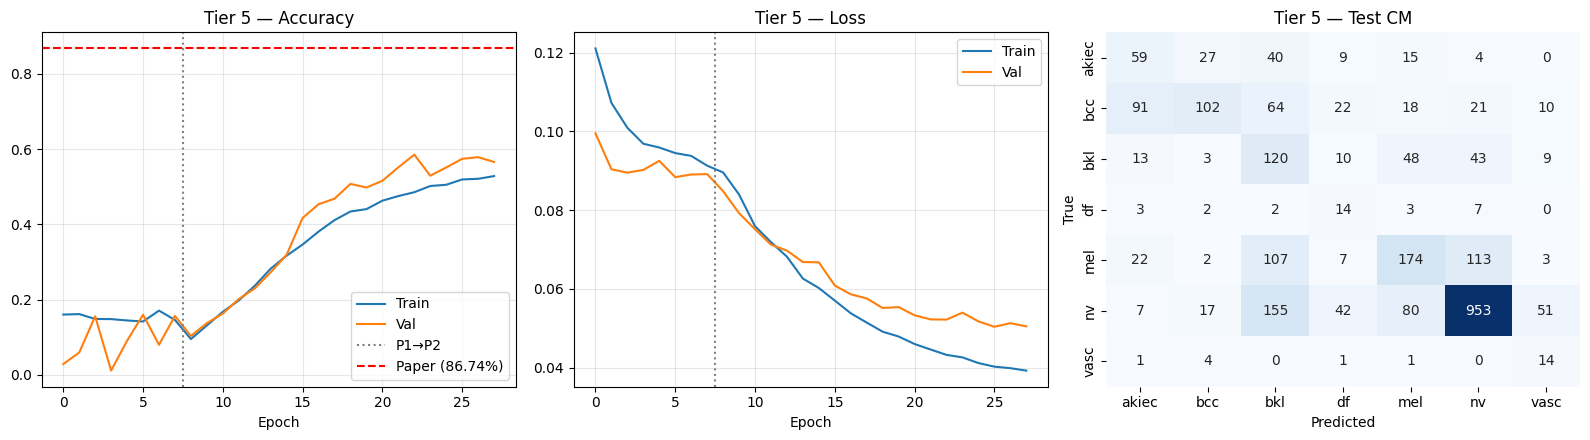


✓ Tier 5 done in 23.0 min
  Test accuracy: 57.14% (paper: 86.74%)

ALL TIERS LP-FT COMPLETE


In [17]:
# ─── Run all tiers ───
all_lpft_results = {}
for tier in TIERS_TO_RUN:
    all_lpft_results[tier] = train_tier_lpft(tier)

print('\n' + '='*70)
print('ALL TIERS LP-FT COMPLETE')
print('='*70)


## 6. Summary + comparison cu Naive (din notebook 01)


In [18]:
rows = []
for tier, res in sorted(all_lpft_results.items()):
    rows.append({
        'tier': tier,
        'epochs': res['phase1_epochs_run'] + res['phase2_epochs_run'],
        'val_acc': res['val']['accuracy'] * 100,
        'val_macro_f1': res['val']['macro_f1'],
        'test_acc': res['test']['accuracy'] * 100,
        'test_macro_f1': res['test']['macro_f1'],
        'test_weighted_f1': res['test']['weighted_f1'],
        'test_auc': res['test']['auc'],
        'time_min': res['time_minutes'],
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

summary_dir = EXPERIMENTS_DIR / 'summary'
summary_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(summary_dir / 'lpft_summary.csv', index=False)
print(f'\nSaved: {summary_dir / "lpft_summary.csv"}')


 tier  epochs  val_acc  val_macro_f1  test_acc  test_macro_f1  test_weighted_f1  test_auc  time_min
    1      33   45.375         0.331    43.494          0.299             0.483     0.789    13.355
    2      32   50.893         0.344    52.209          0.348             0.543     0.799    17.029
    3      30   55.220         0.390    55.869          0.381             0.581     0.838    18.074
    4      29   59.746         0.433    59.172          0.412             0.607     0.854    20.719
    5      28   58.515         0.426    57.143          0.398             0.594     0.857    23.042

Saved: /content/drive/MyDrive/Thesis/experiments/efficientnetv2b0/summary/lpft_summary.csv


In [19]:
# ─── Naive vs LP-FT comparison ───
print(f'\n{"="*70}')
print(f'NAIVE (notebook 01) vs LP-FT (notebook 02)')
print(f'{"="*70}')
print(f'{"Tier":<6} {"Naive Acc":>12} {"LP-FT Acc":>12} {"Δ Acc":>10} {"Naive F1":>12} {"LP-FT F1":>12} {"Δ F1":>10}')
print('-' * 80)

# Naive results path: experiments/efficientnetv2b0_naive/tier{N}/results.json
NAIVE_DIR = DRIVE_BASE / 'experiments' / 'efficientnetv2b0_naive'

for tier in [1, 2, 3, 4, 5]:
    naive_path = NAIVE_DIR / f'tier{tier}' / 'results.json'
    naive_acc = naive_f1 = None
    if naive_path.exists():
        with open(naive_path) as f:
            n = json.load(f)
        naive_acc = n['test']['accuracy'] * 100
        naive_f1 = n['test']['macro_f1']

    lpft = all_lpft_results.get(tier, {})
    lpft_acc = lpft.get('test', {}).get('accuracy', 0) * 100
    lpft_f1 = lpft.get('test', {}).get('macro_f1', 0)

    if naive_acc is not None:
        d_acc = lpft_acc - naive_acc
        d_f1 = lpft_f1 - naive_f1
        print(f'{tier:<6} {naive_acc:>11.2f}% {lpft_acc:>11.2f}% {d_acc:>+9.2f}% '
              f'{naive_f1:>12.4f} {lpft_f1:>12.4f} {d_f1:>+10.4f}')
    else:
        print(f'{tier:<6} {"N/A":>12} {lpft_acc:>11.2f}% {"N/A":>10} '
              f'{"N/A":>12} {lpft_f1:>12.4f} {"N/A":>10}')



NAIVE (notebook 01) vs LP-FT (notebook 02)
Tier      Naive Acc    LP-FT Acc      Δ Acc     Naive F1     LP-FT F1       Δ F1
--------------------------------------------------------------------------------
1            59.61%       43.49%    -16.12%       0.4398       0.2993    -0.1405
2            69.64%       52.21%    -17.43%       0.5810       0.3477    -0.2333
3            65.70%       55.87%     -9.83%       0.5452       0.3811    -0.1641
4            66.02%       59.17%     -6.84%       0.5420       0.4119    -0.1301
5            67.41%       57.14%    -10.27%       0.5289       0.3975    -0.1314
